# Used Car Selling Price Predictor

Predicts a used car's selling price (in lakhs) from its age, mileage, fuel
type, seller type, transmission, and ownership history. Compares a plain
polynomial regression against a Ridge-regularized version and keeps the
better one.

In [1]:
import joblib
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

RANDOM_STATE = 42
MAX_POLY_DEGREE = 3  # degree 4 overfit badly during tuning; capped to keep the model sane

## Load and clean the data

In [2]:
df = pd.read_csv('car_data.csv')
df.columns = df.columns.str.strip()

print(df.dtypes)
print("\nMissing values:\n", df.isnull().sum())
df = df.dropna()

# A car's age is far more predictive than its raw model year, and it
# ages gracefully instead of needing a new dummy variable every year.
current_year = df['Year'].max() + 1
df['Car_Age'] = current_year - df['Year']

df.describe()

Car_Name             str
Year               int64
Selling_Price    float64
Present_Price    float64
Driven_kms         int64
Fuel_Type            str
Selling_type         str
Transmission         str
Owner              int64
dtype: object

Missing values:
 Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
dtype: int64


,Year,Selling_Price,Present_Price,Driven_kms,Owner,Car_Age
count,301.000000,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189,5.372093
std,2.891554,5.082812,8.642584,38886.883882,0.247915,2.891554
min,2003.000000,0.100000,0.320000,500.000000,0.000000,1.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000,3.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000,5.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000,7.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000,16.000000


## Build features

In [3]:
CATEGORICAL_FEATURES = ['Fuel_Type', 'Selling_type', 'Transmission']
FEATURE_COLUMNS = ['Car_Age', 'Driven_kms', 'Owner'] + CATEGORICAL_FEATURES
TARGET_COLUMN = 'Selling_Price'

X = df[FEATURE_COLUMNS]
y = df[TARGET_COLUMN]

X_encoded = pd.get_dummies(X, columns=CATEGORICAL_FEATURES, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=RANDOM_STATE
)

## Choose the polynomial degree via cross-validation

Each candidate degree is scored with 5-fold CV on the *training* set only,
so the held-out test set stays untouched until final evaluation.

In [4]:
scores_by_degree = {}

for degree in range(1, MAX_POLY_DEGREE + 1):
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('model', LinearRegression()),
    ])
    scores = cross_val_score(pipeline, X_train, y_train, cv=5, scoring='r2')
    scores_by_degree[degree] = np.mean(scores)
    print(f"Degree {degree}: mean CV R\u00b2 = {scores_by_degree[degree]:.4f}")

best_degree = max(scores_by_degree, key=scores_by_degree.get)
print(f"\nSelected polynomial degree: {best_degree}")

Degree 1: mean CV R² = 0.5518
Degree 2: mean CV R² = -0.1630
Degree 3: mean CV R² = -260.3979

Selected polynomial degree: 1


## Train and evaluate: Linear Regression

In [5]:
linear_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=best_degree, include_bias=False)),
    ('model', LinearRegression()),
])
linear_pipeline.fit(X_train, y_train)
linear_pred = linear_pipeline.predict(X_test)

linear_rmse = np.sqrt(mean_squared_error(y_test, linear_pred))
linear_r2 = r2_score(y_test, linear_pred)
linear_mae = mean_absolute_error(y_test, linear_pred)

print(f"RMSE: {linear_rmse:.4f}")
print(f"R\u00b2:   {linear_r2:.4f}")
print(f"MAE:  {linear_mae:.4f}")

RMSE: 3.0721
R²:   0.5903
MAE:  2.0410


## Train and evaluate: Ridge Regression

In [6]:
ridge_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=best_degree, include_bias=False)),
    ('model', Ridge(alpha=1.0, random_state=RANDOM_STATE)),
])
ridge_pipeline.fit(X_train, y_train)
ridge_pred = ridge_pipeline.predict(X_test)

ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_pred))
ridge_r2 = r2_score(y_test, ridge_pred)
ridge_mae = mean_absolute_error(y_test, ridge_pred)

print(f"RMSE: {ridge_rmse:.4f}")
print(f"R\u00b2:   {ridge_r2:.4f}")
print(f"MAE:  {ridge_mae:.4f}")

RMSE: 3.0703
R²:   0.5908
MAE:  2.0365


## Residuals of the better model

Best model: Ridge regression (test R² = 0.5908)


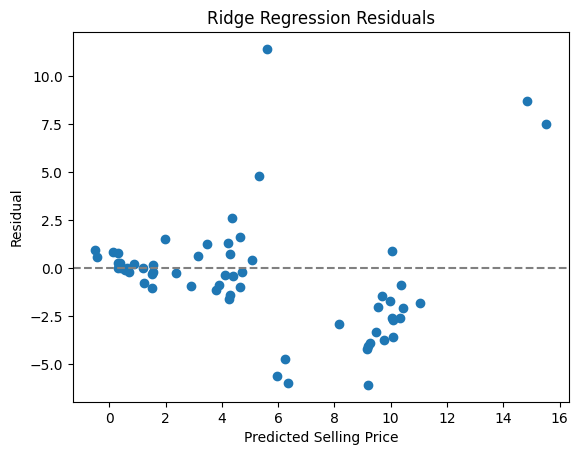

In [7]:
import matplotlib.pyplot as plt

best_name, best_pred, best_r2 = (
    ('Ridge', ridge_pred, ridge_r2) if ridge_r2 > linear_r2 else ('Linear', linear_pred, linear_r2)
)
print(f"Best model: {best_name} regression (test R\u00b2 = {best_r2:.4f})")

residuals = y_test - best_pred
plt.scatter(best_pred, residuals)
plt.axhline(0, color='grey', linestyle='--')
plt.xlabel('Predicted Selling Price')
plt.ylabel('Residual')
plt.title(f'{best_name} Regression Residuals')
plt.show()

## Save the better model

In [8]:
best_pipeline = ridge_pipeline if ridge_r2 > linear_r2 else linear_pipeline
joblib.dump(best_pipeline, 'car_price_model.joblib')
print("Model saved to car_price_model.joblib")

Model saved to car_price_model.joblib
